# Регрессия

Подгружаем данные medical-insurance-payout

Целевая переменная - charges

In [1]:
import pandas as pd
import kagglehub

# Download
df_path = kagglehub.dataset_download("harshsingh2209/medical-insurance-payout", path = "expenses.csv")

# Загрузка данных
df = pd.read_csv(df_path, sep=',')
df

100%|██████████| 54.3k/54.3k [00:00<00:00, 13.6MB/s]


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


# Проведем предобработку данных

Проверим данные на наличие пропущенных значений

In [2]:
missing_counts = df.isnull().sum()
print(missing_counts)

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


В данных нет пропущенных значений, соответственно продолжаем работу

Проведем кодировку качественных признаков

In [3]:
from sklearn.preprocessing import LabelEncoder
# Create a label encoder object
label_encoder = LabelEncoder()

df = df.copy()
# Transform the 'categories' column
df['sex'] = label_encoder.fit_transform(df['sex'].values)
df['smoker'] = label_encoder.fit_transform(df['smoker'].values)

df['region'] = label_encoder.fit_transform(df['region'].values)

df

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,3,16884.92400
1,18,1,33.770,1,0,2,1725.55230
2,28,1,33.000,3,0,2,4449.46200
3,33,1,22.705,0,0,1,21984.47061
4,32,1,28.880,0,0,1,3866.85520
...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,1,10600.54830
1334,18,0,31.920,0,0,0,2205.98080
1335,18,0,36.850,0,0,2,1629.83350
1336,21,0,25.800,0,0,3,2007.94500


Определим целевую переменную и признаки

In [4]:
X = df.drop('charges', axis=1)
y = df['charges']

In [5]:
X

,age,sex,bmi,children,smoker,region
0,19,0,27.900,0,1,3
1,18,1,33.770,1,0,2
2,28,1,33.000,3,0,2
3,33,1,22.705,0,0,1
4,32,1,28.880,0,0,1
...,...,...,...,...,...,...
1333,50,1,30.970,3,0,1
1334,18,0,31.920,0,0,0
1335,18,0,36.850,0,0,2
1336,21,0,25.800,0,0,3


In [6]:
y

,charges
0,16884.92400
1,1725.55230
2,4449.46200
3,21984.47061
4,3866.85520
...,...
1333,10600.54830
1334,2205.98080
1335,1629.83350
1336,2007.94500


Разделим данные на обучающую и тестовую выборки

In [7]:
from sklearn.model_selection import train_test_split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=13)

Проведем стандартизацию данных

In [9]:
from sklearn.preprocessing import StandardScaler

In [10]:
scaler = StandardScaler()
x_train = scaler.fit_transform(X_train)
x_test = scaler.fit_transform(X_test)

# Построим модель нейронной сети для регрессии

Подгружаем необходимые библиотеки ресурсы для работы с нейросетями

In [11]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

Построим модель нейросети, с двумя скрытыми слоями и 64 нейронами

Функция активации - relu

Выходной слой дает одно значение на выходе. Это подходит для построения регрессии, так как мы предсказываем одно значение - целевую переменную

In [12]:
model = keras.Sequential([
    keras.layers.Input(shape=(x_train.shape[1],)),  # Input layer
    keras.layers.Dense(64, activation='relu'), # Hidden layer (1)
    keras.layers.Dense(64, activation='relu'),# Hidden layer (2)
    keras.layers.Dense(1) # output layer (3)
])

In [13]:
model.compile(optimizer='rmsprop', # 'sgd'
              loss="mse", # "mean_absolute_percentage_error"
              metrics=['mae'])

Обучим нейросетевую модель в течении 50 эпох

In [14]:
model.fit(x_train, y_train, epochs=50, batch_size=1, verbose=1)

Epoch 1/50
1070/1070 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 321025120.0000 - mae: 13454.5020
Epoch 2/50
1070/1070 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 290891136.0000 - mae: 11809.2412
Epoch 3/50
1070/1070 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 132990040.0000 - mae: 6738.4863
Epoch 4/50
1070/1070 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 58008568.0000 - mae: 5215.6978
Epoch 5/50
1070/1070 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 42599712.0000 - mae: 4695.6982
Epoch 6/50
1070/1070 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 39846468.0000 - mae: 4376.3120
Epoch 7/50
1070/1070 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 37501720.0000 - mae: 4154.3853
Epoch 8/50
1070/1070 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 36230916.0000 - mae: 3968.0554
Epoch 9/50
1070/1070 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 45140736.0000 - mae: 4417.7500
Epoch 10/50
1070/1070 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 35648400.0000 - mae: 3855.7056
Epoch 11/50
1070/1070 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 3

Выведем метрики оценки точности для модели регрессии на тестовых данных

In [15]:
val_loss, val_mae = model.evaluate(x_test, y_test, verbose=1)
print('Test mae:', val_mae)
print('Test loss:', val_loss)

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 13753041.0000 - mae: 2112.5669  
Test mae: 2085.087890625
Test loss: 13892746.0


Выведем прогноз на тестовых данных

In [16]:
predictions = model.predict(x_test[:4])
predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step


array([[ 2583.5999],
       [12360.644 ],
       [ 3366.7598],
       [ 6201.6787]], dtype=float32)

Таким образом была построена нейронная сеть с выходным слоем с одним нейроном для предсказания целевого показателя charges. Модель имеет большую ошибку на тестовых данных 2085.088, а также большое значени потерь 13892746.0, что говорит о том, что использовать такую модель для прогноза charges не стоит, так как будут получены неточные результаты ( расхождение до нескольких тысяч). При этом при изменении архитектуры и гиперпараметров модели, например, были построены модели с 1, 3, 4 и 5 слоями, а также с различным количеством нейронов, например, 32, 64, 16, 8, 128, ошибка модели возрастает, что говорит о том, чтоданная модель является наиболее оптимальной в нашем случае. Для построения лучшей модели стоило бы попробовать добавить сверточный или прореживающие слои, к примеру, и проанализировать полученные модели.

# Классификация

Также подгрузим необходимые библиотеки и ресурсы для получения нейросетейвой модели классификации

In [144]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from keras.models import Sequential
from keras.layers import Input, Dense
from keras.optimizers import Adam
from sklearn.metrics import accuracy_score, confusion_matrix

Подгрузим данные framingham-heart-study

Целевая переменная - TenYearCHD

In [145]:
import pandas as pd
import kagglehub

# Download
df_path = kagglehub.dataset_download("aasheesh200/framingham-heart-study-dataset", path = "framingham.csv")

# Загрузка данных
df = pd.read_csv(df_path, sep=',')
df

Using Colab cache for faster access to the 'framingham-heart-study-dataset' dataset.


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4235,0,48,2.0,1,20.0,NaN,0,0,0,248.0,131.0,72.0,22.00,84.0,86.0,0
4236,0,44,1.0,1,15.0,0.0,0,0,0,210.0,126.5,87.0,19.16,86.0,NaN,0
4237,0,52,2.0,0,0.0,0.0,0,0,0,269.0,133.5,83.0,21.47,80.0,107.0,0
4238,1,40,3.0,0,0.0,0.0,0,1,0,185.0,141.0,98.0,25.60,67.0,72.0,0


Проведем предобработку данных

In [146]:
missing_counts = df.isnull().sum()
print(missing_counts)

male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64


Заполним пропущенные значения с помощью медианы

In [147]:
df = df.fillna(df.median())
df

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4235,0,48,2.0,1,20.0,0.0,0,0,0,248.0,131.0,72.0,22.00,84.0,86.0,0
4236,0,44,1.0,1,15.0,0.0,0,0,0,210.0,126.5,87.0,19.16,86.0,78.0,0
4237,0,52,2.0,0,0.0,0.0,0,0,0,269.0,133.5,83.0,21.47,80.0,107.0,0
4238,1,40,3.0,0,0.0,0.0,0,1,0,185.0,141.0,98.0,25.60,67.0,72.0,0


In [148]:
missing_counts = df.isnull().sum()
print(missing_counts)

male               0
age                0
education          0
currentSmoker      0
cigsPerDay         0
BPMeds             0
prevalentStroke    0
prevalentHyp       0
diabetes           0
totChol            0
sysBP              0
diaBP              0
BMI                0
heartRate          0
glucose            0
TenYearCHD         0
dtype: int64


Теперь в  данных нет пропущенных значений, соответственно продолжаем работу

Определим целевую переменную и признаки

In [149]:
# Разделение на признаки и целевую переменную
X = df.drop('TenYearCHD', axis=1)
y = df['TenYearCHD']

 Разделение на обучающий и тестовый наборы

In [150]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


Стандартизация признаков

In [151]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [152]:
X_train.shape

(3392, 15)

# Построим нейросетевую модель для классификации

Построим модель нейросети, с 1 скрытым слоем и 10 нейронами

Функция активации - relu

Выходной слой с функцией активации sigmoid преобразует выход в диапазон от 0 до 1, что идеально подходит для задач бинарной классификации (два класса: 0 и 1)

In [26]:
# Создание модели Sequential
model = Sequential()

# Добавление входного и скрытого слоя
model.add(Dense(10, activation='relu'))
# Добавление выходного слоя
model.add(Dense(1, activation='sigmoid'))
# Компиляция модели
model.compile(optimizer=Adam(learning_rate=0.01), loss='binary_crossentropy', metrics=['accuracy'])

In [27]:
# Обучение модели
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.2)

Epoch 1/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7472 - loss: 0.5207 - val_accuracy: 0.8439 - val_loss: 0.3906
Epoch 2/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8522 - loss: 0.3932 - val_accuracy: 0.8439 - val_loss: 0.3748
Epoch 3/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8384 - loss: 0.3956 - val_accuracy: 0.8483 - val_loss: 0.3765
Epoch 4/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8562 - loss: 0.3746 - val_accuracy: 0.8483 - val_loss: 0.3743
Epoch 5/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8564 - loss: 0.3673 - val_accuracy: 0.8513 - val_loss: 0.3700
Epoch 6/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8575 - loss: 0.3625 - val_accuracy: 0.8527 - val_loss: 0.3709
Epoch 7/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8650 - loss: 0.3572 - val_accuracy: 0.8498 - val_loss: 0.3689
Epoch 8/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8594 - loss: 0.3651 - val_accuracy: 0.8557 - val_loss:

Выведем оценки и предсказания на тестовой выборке

In [28]:
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
import pandas as pd

# Предсказание на тестовом наборе
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

# Вычисление метрик
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Вывод всех метрик
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}\n")

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Создание DataFrame для улучшенного отображения матрицы ошибок
conf_matrix_df = pd.DataFrame(conf_matrix,
                              index=['Actual Negative', 'Actual Positive'],
                              columns=['Predicted Negative', 'Predicted Positive'])

print("Confusion Matrix:")
print(conf_matrix_df)

27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
Accuracy: 0.8491
Precision: 0.3333
Recall: 0.0407
F1 Score: 0.0725

Confusion Matrix:
                 Predicted Negative  Predicted Positive
Actual Negative                 715                  10
Actual Positive                 118                   5


Была построена нейронная сеть с выходным слоем с одним нейроном для предсказания целевого показателя TenYearCHD. Что касается точности модели, то можно сказать о том, что рассматривая метрику accuracy, можно сдлеать вывод о том, что модель точна на 84,91%, но при этом, как можно заметить в Confusion Matrix, модель плохо справляется с прогнозированием и выявлением положительных значений. Данная ошибка могла произойти из-за преобладания отрицательных значений над положительными в целом, соответсвенно модель переобучилась, на отрицательных значениях и плохо выявляет положительные. Данную ошибку также подтверждает метрика Precision, которая  отражает соответствие предсказанных положительных величин, реальному количеству положительных величин, то есть только 33% из всех положительных предсказанных величин, действительно положительные. Также появление ошибки с положительными значениями отражает метрика Recall, которая говорит о том, что модель видит только 4,07% всех положительных значений. F1 Score - соотнношение величин Recall и Precision. Её значение крайне низкое 0,07, что также говорит о том, что модель не подходить для получения значимых результатов по положительным значениям и их прогноз соответсвенно. Попробуем улучшить модель за счет изменения архитектуры нейросеети и ее гиперпараметров.

# Улучшим модель нейронной сети

Запускать отдельно, сразу же после предобработки данных

In [171]:
# Создание модели Sequential
model = Sequential()

# Добавление входного и скрытого слоя
model.add(Dense(15, activation='relu'))
model.add(Dense(1, activation='sigmoid'))
# Компиляция модели
model.compile(optimizer=Adam(learning_rate=0.01), loss='binary_crossentropy', metrics=['accuracy'])

In [172]:
# Обучение модели
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.2)

Epoch 1/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8066 - loss: 0.4671 - val_accuracy: 0.8513 - val_loss: 0.3757
Epoch 2/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8485 - loss: 0.3978 - val_accuracy: 0.8498 - val_loss: 0.3691
Epoch 3/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8419 - loss: 0.3898 - val_accuracy: 0.8527 - val_loss: 0.3717
Epoch 4/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8569 - loss: 0.3693 - val_accuracy: 0.8601 - val_loss: 0.3650
Epoch 5/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8443 - loss: 0.3919 - val_accuracy: 0.8586 - val_loss: 0.3682
Epoch 6/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8477 - loss: 0.3667 - val_accuracy: 0.8527 - val_loss: 0.3763
Epoch 7/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8500 - loss: 0.3747 - val_accuracy: 0.8498 - val_loss: 0.3698
Epoch 8/50
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8540 - loss: 0.3680 - val_accuracy: 0.8527 - val_loss:

In [173]:
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
import pandas as pd

# Предсказание на тестовом наборе
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

# Вычисление метрик
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Вывод всех метрик
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}\n")

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Создание DataFrame для улучшенного отображения матрицы ошибок
conf_matrix_df = pd.DataFrame(conf_matrix,
                              index=['Actual Negative', 'Actual Positive'],
                              columns=['Predicted Negative', 'Predicted Positive'])

print("Confusion Matrix:")
print(conf_matrix_df)

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Accuracy: 0.8514
Precision: 0.4286
Recall: 0.0732
F1 Score: 0.1250

Confusion Matrix:
                 Predicted Negative  Predicted Positive
Actual Negative                 713                  12
Actual Positive                 114                   9


Как можно заметить при изменении количества нейронов в модели с 10 до 15, нам удалось получить результат лучше. Точность Accuracy всей модели возрасла до 85,14%. Соотвествие предсказанных положительных значений, реальным составила 42,86% - метрика Precision. Теперь модель видит около 7% всех положительных значений, вместо 4%. А метрика F1 увеличилась с 0,07 до 0,125.Соответвенно можем сказать, что точность модели повысилась вместе с точность определения и прогнозирования положительных значений TenYearCHD. Данная модель больше подходить для прогнозирования и классификации целевой переменной, но все же имеет большую ошибку, при определении положительных значений, если в поставленной задаче наиболее важно определить отрицательное значение TenYearCHD и его прогнозы, то модель можно использовать.

# Временной ряд

Подгрузим необходимые ресурсы и библиотеки и данные об акциях Диснея для построения нейросети

The Walt Disney company (DIS) с yahoo finance

In [72]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import Input, Dense, LSTM
from keras.callbacks import EarlyStopping

# Stock ticker and date range
ticker = "DIS"  # Replace with your desired stock ticker
start_date = "2023-01-01"
end_date = "2024-01-01"

# Step 1: Download stock data from Yahoo Finance
stock_data = yf.download(ticker, start=start_date, end=end_date)
print(stock_data.head())

/tmp/ipython-input-1865803023.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_data = yf.download(ticker, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed

Price           Close       High        Low       Open    Volume
Ticker            DIS        DIS        DIS        DIS       DIS
Date                                                            
2023-01-03  87.511124  88.494726  86.389817  87.520962  14997100
2023-01-04  90.471779  91.229150  87.894737  88.524242  14957200
2023-01-05  90.412743  90.963565  89.025867  90.157011  11622600
2023-01-06  92.379959  93.137337  89.822594  91.140625   9828100
2023-01-09  93.216011  94.130762  91.917656  92.881590  11675800


# Проведем предобработку данных

Выберем целевую переменную - close

In [73]:
feature = 'Close'  # Use the 'Close' price as the feature
prices = stock_data[feature].values.reshape(-1, 1)

Нормализуем данные

In [74]:
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_prices = scaler.fit_transform(prices)

Создадим датасет для построения модели

In [75]:
time_step = 60
X, y = [], []
for i in range(len(scaled_prices) - time_step):
    X.append(scaled_prices[i:i+time_step])
    y.append(scaled_prices[i+time_step])
X, y = np.array(X), np.array(y)

Разделим на обучающую и тестовую выборки

In [76]:
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

# Построим модель для временного ряда

In [34]:
model = Sequential()
model.add(Input(shape=(X_train.shape[1], 1)))
model.add(LSTM(50, return_sequences=True))
model.add(LSTM(50, return_sequences=False))
model.add(Dense(25))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mean_squared_error')

Обучим модель в течении 20 эпох

In [35]:
early_stopping = EarlyStopping(monitor='val_loss', patience=5, min_delta=0.001)

model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_test, y_test), callbacks=[early_stopping])


Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 154ms/step - loss: 0.0775 - val_loss: 0.0213
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - loss: 0.0201 - val_loss: 0.0088
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - loss: 0.0148 - val_loss: 0.0209
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 0.0144 - val_loss: 0.0227
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 0.0121 - val_loss: 0.0121
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - loss: 0.0098 - val_loss: 0.0106
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - loss: 0.0097 - val_loss: 0.0152


Проверим модель на тестовой выборке и выведем метрики оценивания

In [36]:
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions)  # Reverse scaling
y_test_scaled = scaler.inverse_transform(y_test)  # Reverse scaling for actual values
y_train_scaled = scaler.inverse_transform(y_train)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 307ms/step


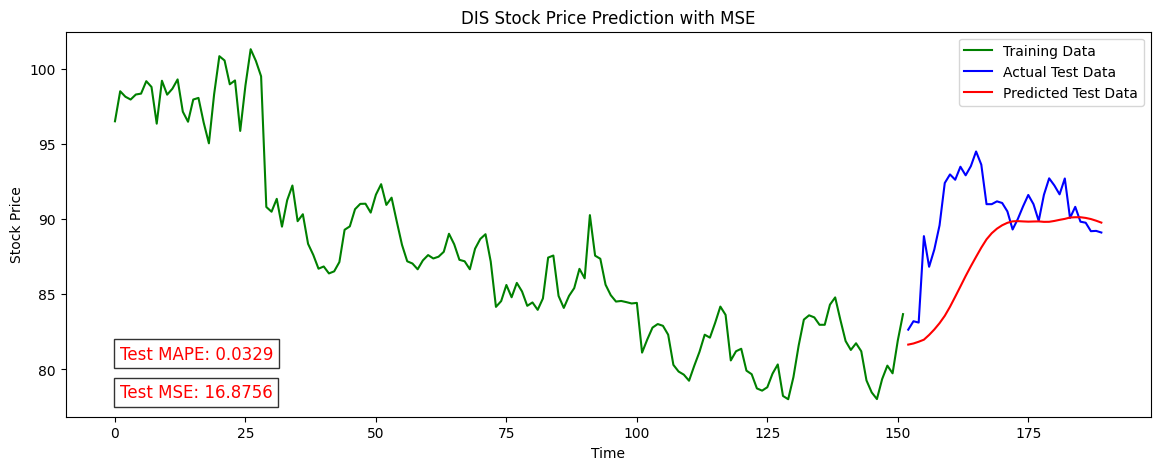

In [37]:
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

# Calculate MSE on test data
mse = mean_squared_error(y_test_scaled, predictions)
mape = mean_absolute_percentage_error(y_test_scaled, predictions)

# Step 7: Plot the results
plt.figure(figsize=(14, 5))

# Plot training data (actual values)
plt.plot(y_train_scaled, color='green', label='Training Data')

# Plot test data (actual values) and predictions
plt.plot(range(len(y_train_scaled), len(y_train_scaled) + len(y_test_scaled)),
         y_test_scaled, color='blue', label='Actual Test Data')
plt.plot(range(len(y_train_scaled), len(y_train_scaled) + len(predictions)),
         predictions, color='red', label='Predicted Test Data')

# Annotate MSE and MAPE on the plot
plt.text(0.05, 0.05, f"Test MSE: {mse:.4f}", transform=plt.gca().transAxes,
         fontsize=12, color='red', bbox=dict(facecolor='white', alpha=0.8))
plt.text(0.05, 0.15, f"Test MAPE: {mape:.4f}", transform=plt.gca().transAxes,
         fontsize=12, color='red', bbox=dict(facecolor='white', alpha=0.8))

# Final plot settings
plt.title(f"{ticker} Stock Price Prediction with MSE")
plt.xlabel('Time')
plt.ylabel('Stock Price')
plt.legend()
plt.show()

Была построена нейронная сеть с выходным слоем с одним нейроном для предсказания цены акций Дисней. Как можно заметить прогнозные значения, вместе с полученными средней квадратической ошибкой и средней абсолютной ошибкой в % были визуализированы на графике. На графике можно увидеть, что построенный нейросетью прогноз повторяет основные тенденции временного ряда (фактически значений), при этом достаточно сильно отклоняется от фактических значений в период, приблизительно,с 150 до 162. С помощью полученной модели можно получить приближенные к реальности прогнозные значения. Абсолютная ошибка прогноза очень мала, средняя квадратическя ошибка 16,876.Попробуем улучшить модель, изменяя ее архитектуру или гиперпараметры, для получения более точного результата.


# Улучшим модель нейронной сети

Запускать отдельно, сразу же после предобработки данных

In [77]:
model = Sequential()
model.add(Input(shape=(X_train.shape[1], 1)))
model.add(LSTM(60, return_sequences=True))
model.add(LSTM(50, return_sequences=False))
model.add(Dense(30))
model.add(Dense(1))
model.compile(optimizer='adam', loss='mean_squared_error')

In [78]:
early_stopping = EarlyStopping(monitor='val_loss', patience=5, min_delta=0.001)

model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_test, y_test), callbacks=[early_stopping])


Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 167ms/step - loss: 0.1084 - val_loss: 0.0311
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 0.0214 - val_loss: 0.0092
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - loss: 0.0209 - val_loss: 0.0166
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - loss: 0.0138 - val_loss: 0.0220
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 0.0165 - val_loss: 0.0109
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - loss: 0.0110 - val_loss: 0.0088
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 0.0091 - val_loss: 0.0119


In [79]:
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions)  # Reverse scaling
y_test_scaled = scaler.inverse_transform(y_test)  # Reverse scaling for actual values
y_train_scaled = scaler.inverse_transform(y_train)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 286ms/step


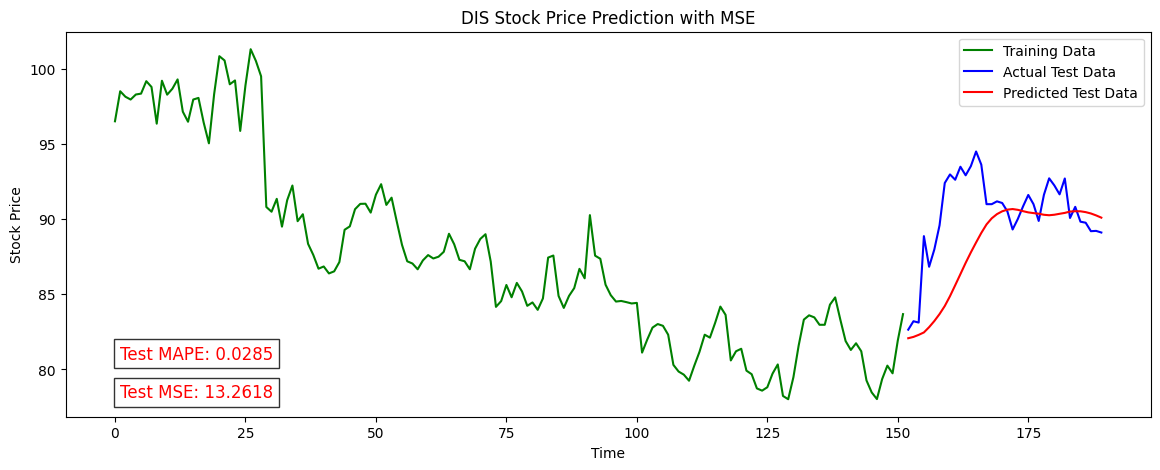

In [80]:
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

# Calculate MSE on test data
mse = mean_squared_error(y_test_scaled, predictions)
mape = mean_absolute_percentage_error(y_test_scaled, predictions)

# Step 7: Plot the results
plt.figure(figsize=(14, 5))

# Plot training data (actual values)
plt.plot(y_train_scaled, color='green', label='Training Data')

# Plot test data (actual values) and predictions
plt.plot(range(len(y_train_scaled), len(y_train_scaled) + len(y_test_scaled)),
         y_test_scaled, color='blue', label='Actual Test Data')
plt.plot(range(len(y_train_scaled), len(y_train_scaled) + len(predictions)),
         predictions, color='red', label='Predicted Test Data')

# Annotate MSE and MAPE on the plot
plt.text(0.05, 0.05, f"Test MSE: {mse:.4f}", transform=plt.gca().transAxes,
         fontsize=12, color='red', bbox=dict(facecolor='white', alpha=0.8))
plt.text(0.05, 0.15, f"Test MAPE: {mape:.4f}", transform=plt.gca().transAxes,
         fontsize=12, color='red', bbox=dict(facecolor='white', alpha=0.8))

# Final plot settings
plt.title(f"{ticker} Stock Price Prediction with MSE")
plt.xlabel('Time')
plt.ylabel('Stock Price')
plt.legend()
plt.show()

Как можно заметить, при изменении количества нейронов с 50 до 60, в скрытом слое, который возвращает последовательности выходов и передает их в следующий слой, качество модели улучшилось. При рассмотрении графика улучшенной модели, можно заметить большее совпадение прогнозных значений с фактическими. Средняя квадратическая ошибка уменьшилась с 16,88 до 13,26, средняя абсолютная ошибка уменьшилась с 0,033 до 0,029. Соответсвенно визуально и за счет метрик оценки качества модели, можем сделать вывод о том, что полученная, улучшенная модель, больше подходит для прогнозирования цен на акции Дисней.

При построении трех различных моделей для прогнозирования различных показателей, можно сказать, что наиболее точной полученной моделью является нейронная сеть для временных рядов. Она имеет достаточно маленью ошибку. С помощью этой модели можно действительно получить приближенный к реалтным данным прогноз о ценах на акции Дисней. На втором месте модель нейронной сети для классификации, с помощью данной модели возможно неплохо спрогнощировать отрицательные значения бинарного показателя, а также определить их с достаточной точностью, но для положительных значений понадобится либо улучшенная модель, либо другой метод, так как точность для положительных значений, их определения и прогнозирования слишком мала. На третьем месте нейронная сеть модели регресси, которая имеет слишком большую ошибку, прогнозирование с помощью такой модели приведет к слишком большому расхождению прогноза с фактичсекими данными, и в дальнейшем к неверным выводам.